# Importing main libraries

In [149]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the store sales dataset

In [152]:
sample = pd.read_csv('sample_submission.csv')
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [154]:
# Check the dimensions of the dataset
print(sample.shape)
print(train.shape) #train data contains the historical sales data
print(test.shape) #test data contains future dates for which the original sales value are not provided

(45000, 2)
(913000, 4)
(45000, 4)


In [156]:
print(sample.head())
print(train.head())
print(test.head())

   id  sales
0   0     52
1   1     52
2   2     52
3   3     52
4   4     52
         date  store  item  sales
0  2013-01-01      1     1     13
1  2013-01-02      1     1     11
2  2013-01-03      1     1     14
3  2013-01-04      1     1     13
4  2013-01-05      1     1     10
   id        date  store  item
0   0  2018-01-01      1     1
1   1  2018-01-02      1     1
2   2  2018-01-03      1     1
3   3  2018-01-04      1     1
4   4  2018-01-05      1     1


# Inspecting the data quality
### Step 2B — What are we checking?
- Missing values: Whether any records have incomplete information.
- Duplicates: Whether identical rows appear more than once.
- Date ranges: Whether training data ends before the test period begins.
- Unique stores and items: We expect 10 stores and 50 items.
- Sales statistics: The minimum, maximum, average and spread of daily unit sales.

In [159]:
# Checking info()
print(train.info())
print(test.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      45000 non-null  int64 
 1   date    45000 non-null  object
 2   store   45000 non-null  int64 
 3   item    45000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.4+ MB
None


In [161]:
# Checking missing values
print(train.isnull().sum())
print(test.isnull().sum())

date     0
store    0
item     0
sales    0
dtype: int64
id       0
date     0
store    0
item     0
dtype: int64


In [163]:
# Checking duplicated values
print(train.duplicated().sum())
print(test.duplicated().sum())

0
0


In [165]:
# Checking data ranges
print("Training dataset:", train['date'].min(),"to", train['date'].max())
print("Testing dataset:", test['date'].min(),"to", test['date'].max())

Training dataset: 2013-01-01 to 2017-12-31
Testing dataset: 2018-01-01 to 2018-03-31


In [167]:
# Checking uniques stores and times
print(train['store'].nunique())
print(test['item'].nunique())

10
50


In [169]:
# Checking sales statistics
print("\nSALES SUMMARY")
print(train["sales"].describe())


SALES SUMMARY
count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64


# Clean and validate the data

In [172]:
train_clean = train.copy()
test_clean = test.copy()

In [174]:
# Convert dates from text to datetime
train_clean["date"] = pd.to_datetime(train_clean["date"])
test_clean["date"] = pd.to_datetime(test_clean["date"])

In [176]:
# Check whether each date-store-item combination is unique
print(
    "Duplicate date-store-item combinations in train:",
    train_clean.duplicated(
        subset=["date", "store", "item"]
    ).sum()
)

print(
    "Duplicate date-store-item combinations in test:",
    test_clean.duplicated(
        subset=["date", "store", "item"]
    ).sum()
)


Duplicate date-store-item combinations in train: 0
Duplicate date-store-item combinations in test: 0


In [178]:
# Check for negative sales values
print("\nNegative sales records:", (train_clean["sales"] < 0).sum())


Negative sales records: 0


In [180]:
# Validate store and item ranges
print("\nStore range:", train_clean["store"].min(),
      "to", train_clean["store"].max())

print("Item range:", train_clean["item"].min(),
      "to", train_clean["item"].max())


Store range: 1 to 10
Item range: 1 to 50


In [182]:
# Confirm date data types
print("\nDate data types:")
print(train_clean["date"].dtype)
print(test_clean["date"].dtype)



Date data types:
datetime64[ns]
datetime64[ns]


In [184]:
# Verify the cleaned datasets
display(train_clean.head())

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


# Exploratory Data Analysis

In [187]:
# Aggregate sales across all stores and items by date
daily_sales = (
    train_clean.groupby("date")["sales"]
    .sum()
    .sort_index()
)

In [189]:
# Display summary statistics
print("Number of unique dates:", daily_sales.shape[0])
print("\nDaily Sales Summary:")
print(daily_sales.describe())


Number of unique dates: 1826

Daily Sales Summary:
count     1826.000000
mean     26125.143483
std       6418.270181
min      11709.000000
25%      21195.000000
50%      25839.500000
75%      30779.500000
max      44936.000000
Name: sales, dtype: float64


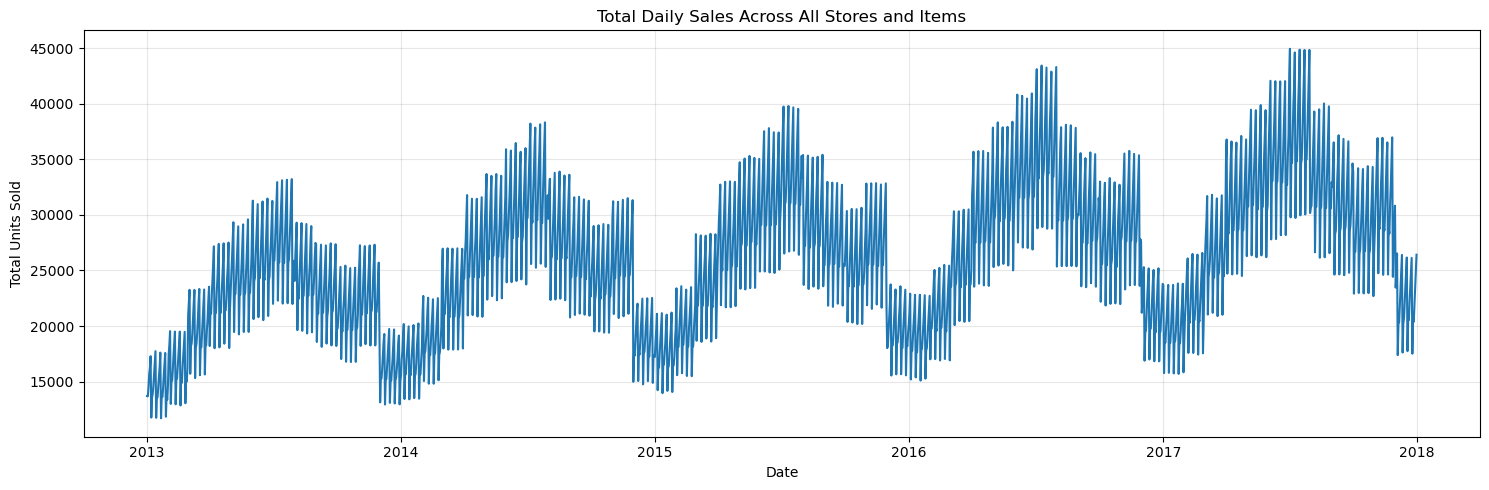

In [191]:
# Plot daily sales over time
plt.figure(figsize=(15, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Total Daily Sales Across All Stores and Items")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [193]:
# Create a DataFrame for seasonal analysis
seasonal_df = daily_sales.to_frame(name="sales")

In [195]:
# Extract weekday and month
seasonal_df["day_of_week"] = seasonal_df.index.dayofweek
seasonal_df["month"] = seasonal_df.index.month


In [197]:
# Map weekday numbers to names
weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}
seasonal_df["weekday_name"] = (
    seasonal_df["day_of_week"].map(weekday_names)
)


In [199]:
# Calculate average sales for each weekday
weekday_sales = seasonal_df.groupby(
    "day_of_week"
)["sales"].mean()

weekday_sales.index = [
    weekday_names[i] for i in weekday_sales.index
]

print("Average Daily Sales by Weekday:")
display(weekday_sales.round(2).to_frame("Average Sales"))


Average Daily Sales by Weekday:


,Average Sales
Monday,20714.82
Tuesday,24112.95
Wednesday,24184.25
Thursday,25861.61
Friday,27578.62
Saturday,29331.35
Sunday,31071.67


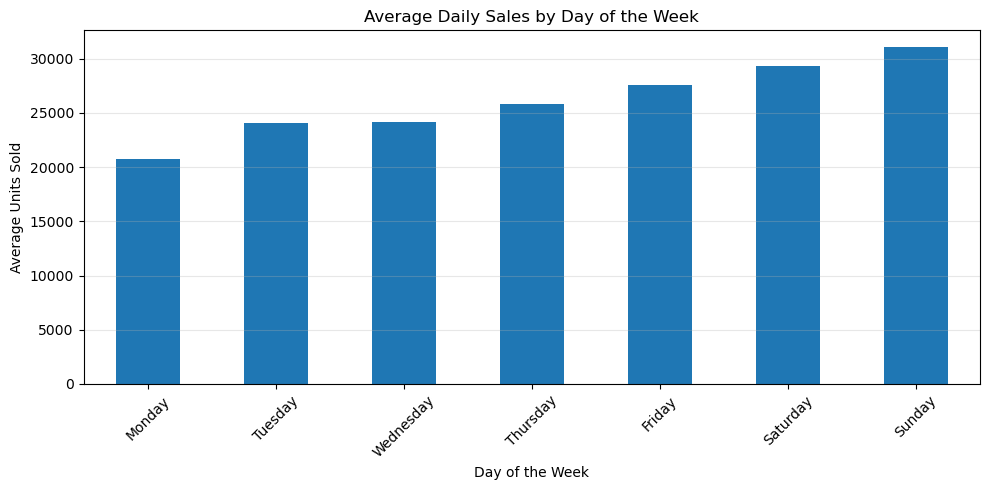

In [201]:
# Plot weekly seasonality
plt.figure(figsize=(10, 5))
weekday_sales.plot(kind="bar")
plt.title("Average Daily Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [203]:
# Calculate average sales for each month
monthly_sales = seasonal_df.groupby(
    "month"
)["sales"].mean()

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_sales.index = month_names

print("\nAverage Daily Sales by Month:")
display(monthly_sales.round(2).to_frame("Average Sales"))



Average Daily Sales by Month:


,Average Sales
Jan,17762.25
Feb,19689.20
Mar,23652.79
Apr,27576.45
May,29564.11
Jun,31512.74
Jul,33499.31
Aug,29552.61
Sep,27536.38
Oct,25596.90


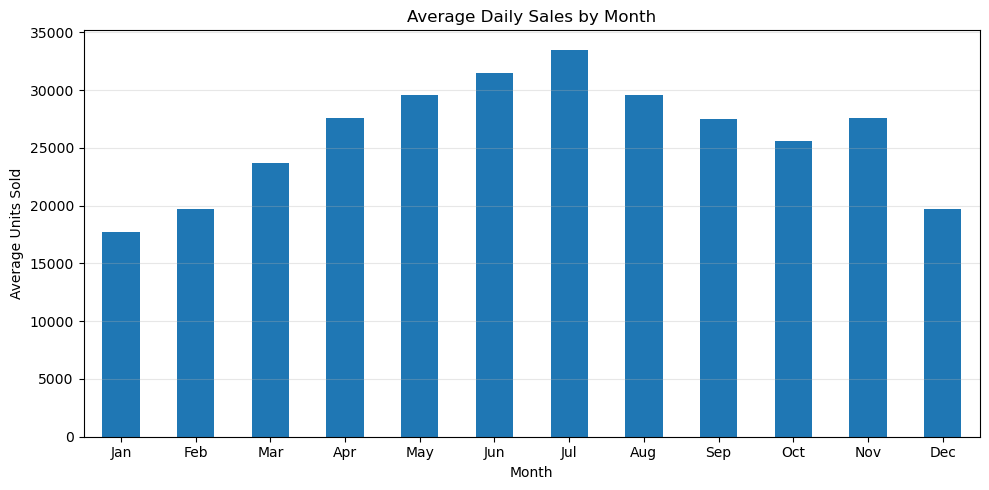

In [205]:
# Plot monthly seasonality
plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="bar")
plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [207]:
# Create a DataFrame for trend analysis
trend_df = daily_sales.to_frame(name="sales")

In [209]:
# Calculate a 7-day rolling average
trend_df["rolling_avg_7"] = (
    trend_df["sales"].rolling(window=7).mean()
)

In [211]:
# Calculate average daily sales for each year
yearly_sales = trend_df.groupby(
    trend_df.index.year
)["sales"].mean()

print("Average Daily Sales by Year:")
display(yearly_sales.round(2).to_frame("Average Sales"))

Average Daily Sales by Year:


,Average Sales
date,
2013,21756.83
2014,25028.72
2015,26128.46
2016,28298.25
2017,29407.51


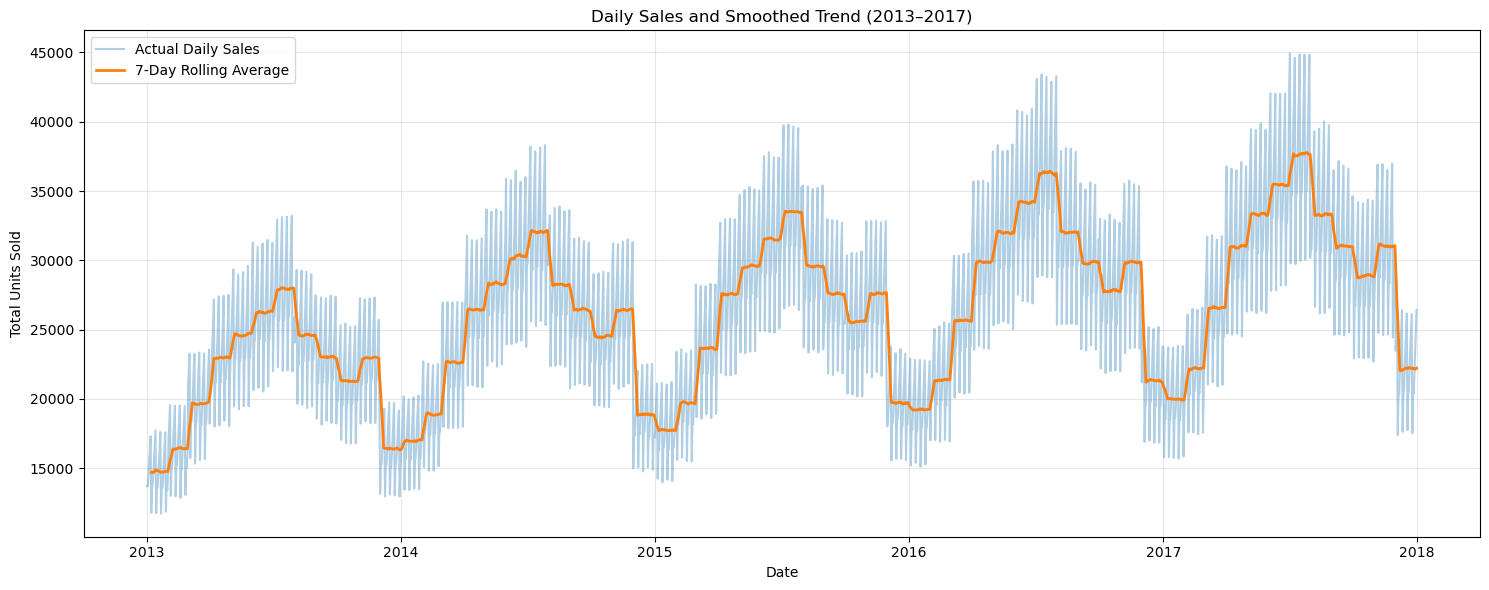

In [213]:
# Plot actual sales and the smoothed trend
plt.figure(figsize=(15, 6))

plt.plot(
    trend_df.index,
    trend_df["sales"],
    alpha=0.35,
    label="Actual Daily Sales"
)

plt.plot(
    trend_df.index,
    trend_df["rolling_avg_7"],
    linewidth=2,
    label="7-Day Rolling Average"
)

plt.title("Daily Sales and Smoothed Trend (2013–2017)")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [215]:
# Identify the 10 highest and lowest sales days
print("\nTop 10 Highest-Sales Days:")
display(
    trend_df.nlargest(10, "sales")[["sales"]]
)

print("\nTop 10 Lowest-Sales Days:")
display(
    trend_df.nsmallest(10, "sales")[["sales"]]
)



Top 10 Highest-Sales Days:


,sales
date,
2017-07-02,44936
2017-07-16,44856
2017-07-30,44832
2017-07-23,44831
2017-07-09,44610
2016-07-10,43427
2016-07-31,43294
2016-07-17,43247
2016-07-03,43103



Top 10 Lowest-Sales Days:


,sales
date,
2013-01-21,11709
2013-01-14,11746
2013-01-07,11769
2013-01-28,11848
2013-02-18,12858
2013-12-09,12942
2013-12-30,12958
2013-02-11,12961
2013-02-04,12998


# Feature Engineering

In [218]:
# Work on a copy of the cleaned training data
model_data = train_clean.copy()

In [220]:
# Sort chronologically within each store-item combination
model_data = model_data.sort_values(
    ["store", "item", "date"]
).reset_index(drop=True)


In [222]:
# Calendar features
model_data["year"] = model_data["date"].dt.year
model_data["month"] = model_data["date"].dt.month
model_data["day_of_week"] = model_data["date"].dt.dayofweek
model_data["day_of_month"] = model_data["date"].dt.day
model_data["is_weekend"] = (
    model_data["day_of_week"] >= 5
).astype(int)


In [224]:
# Create lag and rolling features for each store-item series
grouped_sales = model_data.groupby(["store", "item"])["sales"]

for lag in [7, 14, 28]:
    model_data[f"lag_{lag}"] = grouped_sales.shift(lag)

# Rolling means use only previous days, not the current day's sales
for window in [7, 28]:
    model_data[f"rolling_mean_{window}"] = (
        model_data.groupby(["store", "item"])["sales"]
        .transform(
            lambda s: s.shift(1).rolling(window).mean()
        )
    )


In [225]:
# Inspect the engineered features
print("Shape before feature engineering:", train_clean.shape)
print("Shape after feature engineering:", model_data.shape)

print("\nColumns:")
print(model_data.columns.tolist())

print("\nFirst five rows:")
display(model_data.head())

print("\nMissing values in engineered features:")
display(model_data.isnull().sum().to_frame("Missing Values"))

Shape before feature engineering: (913000, 4)
Shape after feature engineering: (913000, 14)

Columns:
['date', 'store', 'item', 'sales', 'year', 'month', 'day_of_week', 'day_of_month', 'is_weekend', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']

First five rows:


,date,store,item,sales,year,month,day_of_week,day_of_month,is_weekend,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
0,2013-01-01,1,1,13,2013,1,1,1,0,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,1,1,11,2013,1,2,2,0,NaN,NaN,NaN,NaN,NaN
2,2013-01-03,1,1,14,2013,1,3,3,0,NaN,NaN,NaN,NaN,NaN
3,2013-01-04,1,1,13,2013,1,4,4,0,NaN,NaN,NaN,NaN,NaN
4,2013-01-05,1,1,10,2013,1,5,5,1,NaN,NaN,NaN,NaN,NaN



Missing values in engineered features:


,Missing Values
date,0
store,0
item,0
sales,0
year,0
month,0
day_of_week,0
day_of_month,0
is_weekend,0
lag_7,3500


In [228]:
# Define the features we will use
feature_cols = [
    "store",
    "item",
    "year",
    "month",
    "day_of_week",
    "day_of_month",
    "is_weekend",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

In [230]:
# Remove rows without sufficient historical sales information
model_data_clean = model_data.dropna(
    subset=feature_cols
).copy()

In [232]:
# Sort globally by date for time-series validation
model_data_clean = model_data_clean.sort_values(
    "date"
).reset_index(drop=True)

In [234]:
# Check the result
print("Rows before removing missing features:", len(model_data))
print("Rows after removing missing features:", len(model_data_clean))
print("Rows removed:", len(model_data) - len(model_data_clean))

print("\nRemaining missing values in features:")
display(
    model_data_clean[feature_cols]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

print("\nAvailable date range:")
print(
    model_data_clean["date"].min(),
    "to",
    model_data_clean["date"].max()
)

print("\nFirst five rows:")
display(model_data_clean.head())

Rows before removing missing features: 913000
Rows after removing missing features: 899000
Rows removed: 14000

Remaining missing values in features:


,Missing Values
store,0
item,0
year,0
month,0
day_of_week,0
day_of_month,0
is_weekend,0
lag_7,0
lag_14,0
lag_28,0



Available date range:
2013-01-29 00:00:00 to 2017-12-31 00:00:00

First five rows:


,date,store,item,sales,year,month,day_of_week,day_of_month,is_weekend,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
0,2013-01-29,1,1,6,2013,1,1,29,0,7.0,5.0,13.0,10.428571,10.714286
1,2013-01-29,3,16,10,2013,1,1,29,0,13.0,18.0,15.0,15.428571,15.785714
2,2013-01-29,3,17,19,2013,1,1,29,0,20.0,21.0,26.0,22.000000,20.964286
3,2013-01-29,10,6,40,2013,1,1,29,0,22.0,40.0,32.0,35.857143,37.892857
4,2013-01-29,3,18,49,2013,1,1,29,0,51.0,52.0,45.0,53.428571,51.500000


# Create a chronological train-validation split

In [237]:
# Define the validation start date
validation_start = pd.Timestamp("2017-10-01")

In [239]:
# Split chronologically — never shuffle time-series data
train_model = model_data_clean[
    model_data_clean["date"] < validation_start
].copy()

val_model = model_data_clean[
    model_data_clean["date"] >= validation_start
].copy()


In [241]:
# Separate features and target
X_train = train_model[feature_cols]
y_train = train_model["sales"]

X_val = val_model[feature_cols]
y_val = val_model["sales"]

In [243]:
# Verify the split
print("TRAINING SET")
print("Rows:", len(train_model))
print("Date range:", train_model["date"].min(),
      "to", train_model["date"].max())

print("\nVALIDATION SET")
print("Rows:", len(val_model))
print("Date range:", val_model["date"].min(),
      "to", val_model["date"].max())

print("\nFeature matrix shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)


TRAINING SET
Rows: 853000
Date range: 2013-01-29 00:00:00 to 2017-09-30 00:00:00

VALIDATION SET
Rows: 46000
Date range: 2017-10-01 00:00:00 to 2017-12-31 00:00:00

Feature matrix shapes:
X_train: (853000, 12)
y_train: (853000,)
X_val: (46000, 12)
y_val: (46000,)


In [245]:
# Confirm that the periods do not overlap
print("\nTraining and validation overlap:",
      train_model["date"].max() >= val_model["date"].min())


Training and validation overlap: False


In [247]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [249]:
# Baseline predictions: sales from 7 days earlier
baseline_predictions = val_model["lag_7"].to_numpy()

# Actual validation sales
actual_sales = y_val.to_numpy()


In [251]:
# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    actual_sales, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(actual_sales, baseline_predictions)
)


In [253]:
# Calculate MAPE only for observations with nonzero actual sales
nonzero_mask = actual_sales != 0

baseline_mape = np.mean(
    np.abs(
        (actual_sales[nonzero_mask] -
         baseline_predictions[nonzero_mask])
        / actual_sales[nonzero_mask]
    )
) * 100

print("SEASONAL-NAIVE BASELINE RESULTS")
print(f"MAE:  {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"MAPE: {baseline_mape:.2f}%")

SEASONAL-NAIVE BASELINE RESULTS
MAE:  9.0763
RMSE: 12.0507
MAPE: 19.92%


In [255]:
from sklearn.linear_model import LinearRegression


In [257]:
# Train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [259]:
# Predict sales for the validation period
lr_predictions = lr_model.predict(X_val)

In [261]:
# Calculate evaluation metrics
lr_mae = mean_absolute_error(y_val, lr_predictions)

lr_rmse = np.sqrt(
    mean_squared_error(y_val, lr_predictions)
)

actual = y_val.to_numpy()
nonzero_mask = actual != 0

lr_mape = np.mean(
    np.abs(
        (actual[nonzero_mask] -
         lr_predictions[nonzero_mask])
        / actual[nonzero_mask]
    )
) * 100

print("LINEAR REGRESSION RESULTS")
print(f"MAE:  {lr_mae:.4f}")
print(f"RMSE: {lr_rmse:.4f}")
print(f"MAPE: {lr_mape:.2f}%")

LINEAR REGRESSION RESULTS
MAE:  7.0585
RMSE: 9.2741
MAPE: 15.41%


In [263]:
# Comparing Linear Regression against the baseline
comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "Linear Regression"],
    "MAE": [baseline_mae, lr_mae],
    "RMSE": [baseline_rmse, lr_rmse],
    "MAPE (%)": [baseline_mape, lr_mape]
})

display(comparison.round(4))

,Model,MAE,RMSE,MAPE (%)
0,Seasonal Naive,9.0763,12.0507,19.917
1,Linear Regression,7.0585,9.2741,15.410


In [266]:
from sklearn.ensemble import RandomForestRegressor

In [268]:
# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

In [270]:
rf_model.fit(X_train, y_train)
print("Random Forest training completed.")

Random Forest training completed.


In [272]:
rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_predictions)
)

actual = y_val.to_numpy()
nonzero_mask = actual != 0

rf_mape = np.mean(
    np.abs(
        (actual[nonzero_mask] -
         rf_predictions[nonzero_mask])
        / actual[nonzero_mask]
    )
) * 100

print("RANDOM FOREST RESULTS")
print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"MAPE: {rf_mape:.2f}%")


RANDOM FOREST RESULTS
MAE:  6.1511
RMSE: 8.0095
MAPE: 13.43%


In [274]:
# Compare all three models
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [baseline_mae, lr_mae, rf_mae],
    "RMSE": [baseline_rmse, lr_rmse, rf_rmse],
    "MAPE (%)": [
        baseline_mape, lr_mape, rf_mape
    ]
})

display(comparison.round(4))


,Model,MAE,RMSE,MAPE (%)
0,Seasonal Naive,9.0763,12.0507,19.9170
1,Linear Regression,7.0585,9.2741,15.4100
2,Random Forest,6.1511,8.0095,13.4272


# Understand which features influence sales predictions

In [277]:
# Extract feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
})

In [283]:
# Sort from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
print("Feature Importance Ranking:")
display(feature_importance.round(4))


Feature Importance Ranking:


,Feature,Importance
7,lag_7,0.6770
10,rolling_mean_7,0.2301
8,lag_14,0.0319
4,day_of_week,0.0214
11,rolling_mean_28,0.0192
3,month,0.0069
5,day_of_month,0.0045
9,lag_28,0.0042
6,is_weekend,0.0019
1,item,0.0015


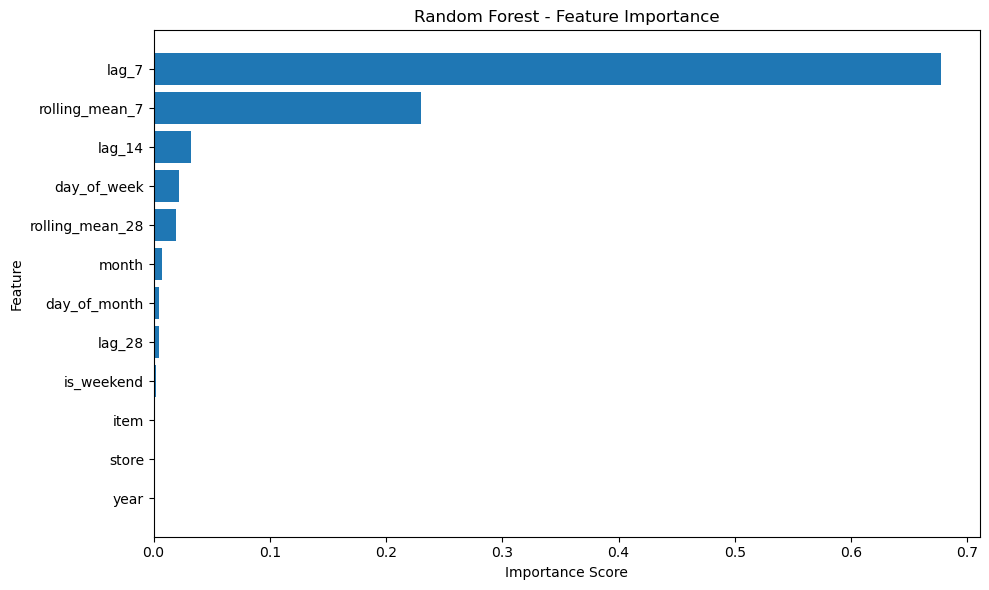

In [285]:
# Visualize the top features
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [287]:
# Select one store-item combination
store_id = 1
item_id = 1

# Filter the last 30 validation days for this combination
plot_data = val_model[
    (val_model["store"] == store_id) &
    (val_model["item"] == item_id)
].copy()

# Add predictions for the same rows
plot_data["predicted_sales"] = rf_model.predict(
    plot_data[feature_cols]
)

plot_data = plot_data.tail(30)

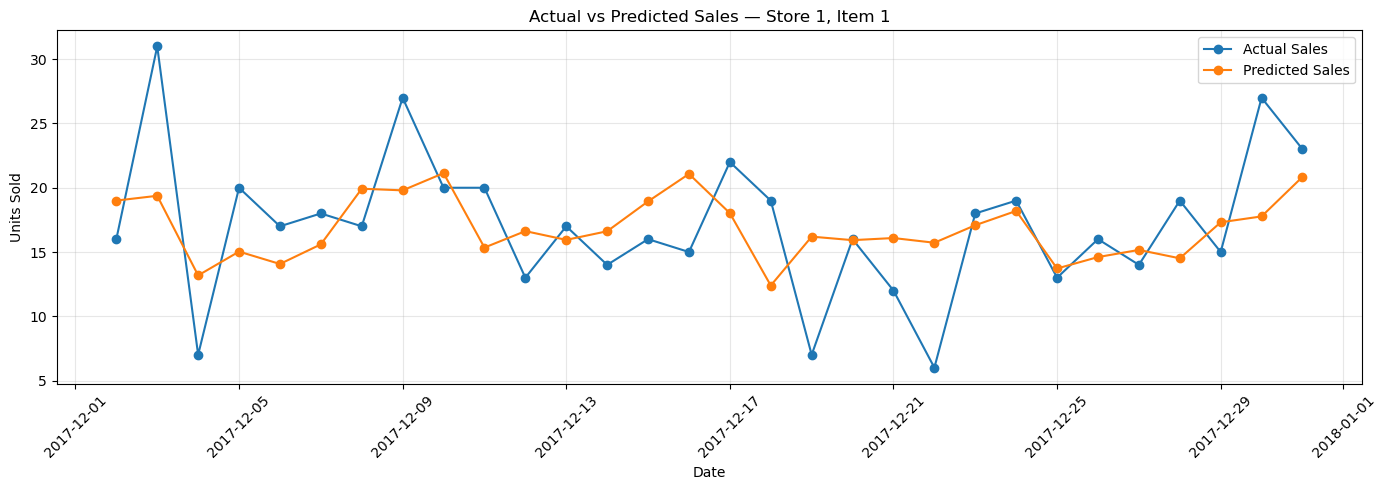

In [291]:
# Plot actual versus predicted sales
plt.figure(figsize=(14, 5))

plt.plot(
    plot_data["date"],
    plot_data["sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    plot_data["date"],
    plot_data["predicted_sales"],
    marker="o",
    label="Predicted Sales"
)

plt.title(
    f"Actual vs Predicted Sales — Store {store_id}, Item {item_id}"
)
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [293]:
# Inspect the prediction errors
plot_data["error"] = (
    plot_data["sales"] - plot_data["predicted_sales"]
)

display(
    plot_data[["date", "sales", "predicted_sales", "error"]]
    .round(2)
)

,date,sales,predicted_sales,error
884438,2017-12-02,16,19.00,-3.00
884998,2017-12-03,31,19.37,11.63
885288,2017-12-04,7,13.18,-6.18
885771,2017-12-05,20,15.03,4.97
886373,2017-12-06,17,14.07,2.93
886681,2017-12-07,18,15.60,2.40
887159,2017-12-08,17,19.92,-2.92
887905,2017-12-09,27,19.80,7.20
888409,2017-12-10,20,21.14,-1.14
888958,2017-12-11,20,15.34,4.66


In [295]:
## Calculate the model's error for this store-item combination

In [303]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [305]:
actual = plot_data["sales"]
predicted = plot_data["predicted_sales"]

mae_30 = mean_absolute_error(actual, predicted)
rmse_30 = np.sqrt(mean_squared_error(actual, predicted))


In [307]:
nonzero = actual != 0
mape_30 = (
    np.mean(np.abs(
        (actual[nonzero] - predicted[nonzero]) / actual[nonzero]
    )) * 100
)

print("STORE-ITEM LEVEL ERROR ANALYSIS")
print(f"MAE:  {mae_30:.2f}")
print(f"RMSE: {rmse_30:.2f}")
print(f"MAPE: {mape_30:.2f}%")


STORE-ITEM LEVEL ERROR ANALYSIS
MAE:  4.01
RMSE: 4.99
MAPE: 29.32%


# Prepare the test dataset for forecasting

In [312]:

# Inspect the test dataset
test_clean = test_clean.sort_values(
    ["store", "item", "date"]
).reset_index(drop=True)

print("TEST DATA SUMMARY")
print("Rows:", len(test_clean))
print("Unique stores:", test_clean["store"].nunique())
print("Unique items:", test_clean["item"].nunique())
print(
    "Date range:",
    test_clean["date"].min(),
    "to",
    test_clean["date"].max()
)

print("\nRows per date:")
display(test_clean.groupby("date").size().describe())

print("\nFirst five test rows:")
display(test_clean.head())


TEST DATA SUMMARY
Rows: 45000
Unique stores: 10
Unique items: 50
Date range: 2018-01-01 00:00:00 to 2018-03-31 00:00:00

Rows per date:


count     90.0
mean     500.0
std        0.0
min      500.0
25%      500.0
50%      500.0
75%      500.0
max      500.0
dtype: float64


First five test rows:


,id,date,store,item
0,0,2018-01-01,1,1
1,1,2018-01-02,1,1
2,2,2018-01-03,1,1
3,3,2018-01-04,1,1
4,4,2018-01-05,1,1


In [314]:
# Generate future sales forecasts

In [316]:
# Start with all observed historical sales
history = train_clean[
    ["date", "store", "item", "sales"]
].copy()

history["date"] = pd.to_datetime(history["date"])

# Store forecasts here
forecast_rows = []

# Forecast dates in chronological order
forecast_dates = sorted(test_clean["date"].unique())

In [320]:
# Create lookup for test combinations by date
test_by_date = {
    date: group[["id", "date", "store", "item"]].copy()
    for date, group in test_clean.groupby("date")
}

for current_date in forecast_dates:
    current_date = pd.Timestamp(current_date)

    # Get the store-item combinations for this date
    current = test_by_date[current_date].copy()

    # Calendar features
    current["year"] = current_date.year
    current["month"] = current_date.month
    current["day_of_week"] = current_date.dayofweek
    current["day_of_month"] = current_date.day
    current["is_weekend"] = (
        current["day_of_week"] >= 5
    ).astype(int)

    # Historical data up to the previous day
    for index, row in current.iterrows():
        store = row["store"]
        item = row["item"]

        series = history[
            (history["store"] == store) &
            (history["item"] == item)
        ].sort_values("date")

        sales_values = series["sales"].to_numpy()

        # The most recent observed or predicted sales
        current.loc[index, "lag_7"] = sales_values[-7]
        current.loc[index, "lag_14"] = sales_values[-14]
        current.loc[index, "lag_28"] = sales_values[-28]

        current.loc[index, "rolling_mean_7"] = np.mean(
            sales_values[-7:]
        )
        current.loc[index, "rolling_mean_28"] = np.mean(
            sales_values[-28:]
        )

    # Generate predictions for today's combinations
    current["predicted_sales"] = rf_model.predict(
        current[feature_cols]
    )

    # Sales cannot be negative
    current["predicted_sales"] = (
        current["predicted_sales"].clip(lower=0)
    )

    # Save forecasts
    forecast_rows.append(
        current[
            ["id", "date", "store", "item", "predicted_sales"]
        ].copy()
    )

    # Add today's predictions to history for future lags
    new_history = current[
        ["date", "store", "item", "predicted_sales"]
    ].rename(columns={"predicted_sales": "sales"})

    history = pd.concat(
        [history, new_history],
        ignore_index=True
    )

    if current_date.day == 1:
        print("Forecasting:", current_date.date())

Forecasting: 2018-01-01
Forecasting: 2018-02-01
Forecasting: 2018-03-01


In [321]:
# Combine all forecasts
forecast_df = pd.concat(forecast_rows, ignore_index=True)

print("\nFORECAST COMPLETE")
print("Forecast rows:", len(forecast_df))
print(
    "Forecast date range:",
    forecast_df["date"].min(),
    "to",
    forecast_df["date"].max()
)

display(forecast_df.head())



FORECAST COMPLETE
Forecast rows: 45000
Forecast date range: 2018-01-01 00:00:00 to 2018-03-31 00:00:00


,id,date,store,item,predicted_sales
0,0,2018-01-01,1,1,13.711765
1,900,2018-01-01,1,2,37.450423
2,1800,2018-01-01,1,3,22.809254
3,2700,2018-01-01,1,4,13.699670
4,3600,2018-01-01,1,5,11.655103


In [324]:
# Validate the forecast output

print("Total forecast rows:", len(forecast_df))
print("Unique forecast IDs:", forecast_df["id"].nunique())
print("Missing predictions:", forecast_df["predicted_sales"].isna().sum())
print("Negative predictions:", (forecast_df["predicted_sales"] < 0).sum())

print("\nForecast statistics:")
display(forecast_df["predicted_sales"].describe().round(2))

# Check whether every test ID has exactly one prediction
print(
    "\nEvery test ID predicted exactly once:",
    forecast_df["id"].is_unique
)

print(
    "All test IDs covered:",
    set(forecast_df["id"]) == set(test_clean["id"])
)

Total forecast rows: 45000
Unique forecast IDs: 45000
Missing predictions: 0
Negative predictions: 0

Forecast statistics:


count    45000.00
mean        50.78
std         25.72
min          8.68
25%         29.56
50%         46.50
75%         67.97
max        144.63
Name: predicted_sales, dtype: float64


Every test ID predicted exactly once: True
All test IDs covered: True


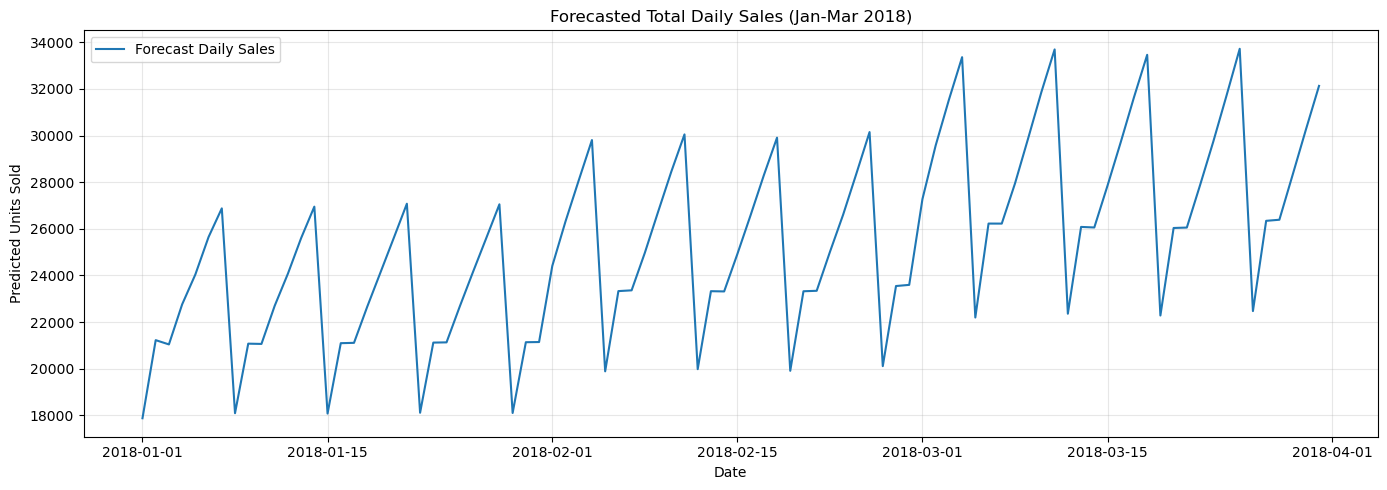

Average forecast daily sales: 25387.74
Minimum forecast daily sales: 17878.32
Maximum forecast daily sales: 33718.34


In [326]:
# Aggregate predictions by date
daily_forecast = (
    forecast_df.groupby("date")["predicted_sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    daily_forecast.index,
    daily_forecast.values,
    label="Forecast Daily Sales"
)

plt.title("Forecasted Total Daily Sales (Jan-Mar 2018)")
plt.xlabel("Date")
plt.ylabel("Predicted Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Average forecast daily sales:", round(daily_forecast.mean(), 2))
print("Minimum forecast daily sales:", round(daily_forecast.min(), 2))
print("Maximum forecast daily sales:", round(daily_forecast.max(), 2))

In [328]:
# Match the original sample submission format
submission = (
    forecast_df[["id", "predicted_sales"]]
    .rename(columns={"predicted_sales": "sales"})
    .sort_values("id")
)

submission.to_csv("sales_forecast_submission.csv", index=False)

print("Submission file saved successfully.")
display(submission.head())

Submission file saved successfully.


,id,sales
0,0,13.711765
500,1,16.122360
1000,2,15.768751
1500,3,16.256770
2000,4,17.469628


In [330]:
# Check the aggregate forecast pattern by day of week

forecast_check = forecast_df.copy()
forecast_check["date"] = pd.to_datetime(forecast_check["date"])
forecast_check["day_of_week"] = (
    forecast_check["date"].dt.day_name()
)

weekday_summary = (
    forecast_check.groupby("day_of_week")["predicted_sales"]
    .agg(["mean", "median", "std"])
    .round(2)
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

display(weekday_summary.reindex(weekday_order))

,mean,median,std
day_of_week,,,
Monday,39.92,37.02,19.42
Tuesday,46.75,43.52,22.77
Wednesday,46.74,43.54,22.78
Thursday,50.67,46.69,24.57
Friday,54.12,50.03,26.16
Saturday,57.61,54.03,28.01
Sunday,60.35,56.14,29.47


In [334]:
# Inspect total predicted sales for the first 14 days
daily_check = (
    forecast_check.groupby("date")["predicted_sales"]
    .sum()
    .sort_index()
)

display(daily_check.head(14).round(2))

date
2018-01-01    17878.32
2018-01-02    21226.96
2018-01-03    21044.16
2018-01-04    22759.93
2018-01-05    24043.45
2018-01-06    25649.91
2018-01-07    26877.28
2018-01-08    18094.44
2018-01-09    21076.37
2018-01-10    21064.92
2018-01-11    22698.39
2018-01-12    24075.81
2018-01-13    25600.71
2018-01-14    26951.12
Name: predicted_sales, dtype: float64

In [336]:

# Compare actual historical and predicted sales by weekday

historical_check = train_clean.copy()
historical_check["date"] = pd.to_datetime(
    historical_check["date"]
)

historical_check["day_of_week"] = (
    historical_check["date"].dt.day_name()
)

actual_weekday = (
    historical_check.groupby("day_of_week")["sales"]
    .mean()
    .rename("Historical Average")
)

predicted_weekday = (
    forecast_check.groupby("day_of_week")["predicted_sales"]
    .mean()
    .rename("Forecast Average")
)

weekday_comparison = pd.concat(
    [actual_weekday, predicted_weekday],
    axis=1
).reindex(weekday_order)

weekday_comparison["Difference (%)"] = (
    (weekday_comparison["Forecast Average"]
     - weekday_comparison["Historical Average"])
    / weekday_comparison["Historical Average"]
    * 100
).round(2)

display(weekday_comparison.round(2))


,Historical Average,Forecast Average,Difference (%)
day_of_week,,,
Monday,41.43,39.92,-3.64
Tuesday,48.23,46.75,-3.06
Wednesday,48.37,46.74,-3.36
Thursday,51.72,50.67,-2.04
Friday,55.16,54.12,-1.88
Saturday,58.66,57.61,-1.79
Sunday,62.14,60.35,-2.89


In [338]:

# Compare weekly aggregate sales patterns

historical_daily = (
    train_clean.groupby("date")["sales"]
    .sum()
    .sort_index()
)

forecast_daily = (
    forecast_df.groupby("date")["predicted_sales"]
    .sum()
    .sort_index()
)

historical_weekly = historical_daily.resample("W").mean()
forecast_weekly = forecast_daily.resample("W").mean()

print("Historical daily average:",
      round(historical_daily.mean(), 2))

print("Forecast daily average:",
      round(forecast_daily.mean(), 2))

print("Historical daily standard deviation:",
      round(historical_daily.std(), 2))

print("Forecast daily standard deviation:",
      round(forecast_daily.std(), 2))

print("\nFirst 10 forecast days:")
display(forecast_daily.head(10).round(2))


Historical daily average: 26125.14
Forecast daily average: 25387.74
Historical daily standard deviation: 6418.27
Forecast daily standard deviation: 3988.25

First 10 forecast days:


date
2018-01-01    17878.32
2018-01-02    21226.96
2018-01-03    21044.16
2018-01-04    22759.93
2018-01-05    24043.45
2018-01-06    25649.91
2018-01-07    26877.28
2018-01-08    18094.44
2018-01-09    21076.37
2018-01-10    21064.92
Name: predicted_sales, dtype: float64

In [340]:

# Evaluate Random Forest performance by store-item combination

validation_results = val_model[
    ["store", "item", "date", "sales"]
].copy()

validation_results["predicted_sales"] = rf_predictions

validation_results["absolute_error"] = (
    validation_results["sales"]
    - validation_results["predicted_sales"]
).abs()

combination_errors = (
    validation_results
    .groupby(["store", "item"])
    .agg(
        MAE=("absolute_error", "mean"),
        Actual_Avg=("sales", "mean"),
        Predicted_Avg=("predicted_sales", "mean")
    )
    .reset_index()
)

combination_errors["MAE"] = combination_errors["MAE"].round(2)
combination_errors["Actual_Avg"] = (
    combination_errors["Actual_Avg"].round(2)
)
combination_errors["Predicted_Avg"] = (
    combination_errors["Predicted_Avg"].round(2)
)

print("Store-item combinations evaluated:",
      len(combination_errors))

print("\nFive combinations with the highest MAE:")
display(
    combination_errors.nlargest(5, "MAE")
)

print("\nFive combinations with the lowest MAE:")
display(
    combination_errors.nsmallest(5, "MAE")
)


Store-item combinations evaluated: 500

Five combinations with the highest MAE:


,store,item,MAE,Actual_Avg,Predicted_Avg
377,8,28,11.46,113.84,109.52
77,2,28,11.44,117.51,115.17
64,2,15,10.94,117.04,113.36
94,2,45,10.74,109.11,105.40
74,2,25,10.33,108.75,106.48



Five combinations with the lowest MAE:


,store,item,MAE,Actual_Avg,Predicted_Avg
346,7,47,2.86,15.97,16.45
296,6,47,2.89,16.82,16.81
265,6,16,3.02,20.46,20.27
204,5,5,3.07,14.92,14.92
450,10,1,3.13,25.48,25.41


In [346]:
# Compare row-level and store-item-level validation errors

overall_mae = validation_results["absolute_error"].mean()

macro_mae = combination_errors["MAE"].mean()

print(f"Overall validation MAE: {overall_mae:.4f}")
print(f"Average store-item MAE: {macro_mae:.4f}")

print("\nMAE distribution across store-item combinations:")
display(
    combination_errors["MAE"].describe().round(2)
)

Overall validation MAE: 6.1511
Average store-item MAE: 6.1514

MAE distribution across store-item combinations:


count    500.00
mean       6.15
std        1.73
min        2.86
25%        4.74
50%        6.10
75%        7.34
max       11.46
Name: MAE, dtype: float64

# Deployment

In [350]:

import os
import joblib
import pandas as pd

# Create a folder for the app's required files
os.makedirs("artifacts", exist_ok=True)

# Save the trained Random Forest model and feature order
joblib.dump(
    {
        "model": rf_model,
        "feature_cols": feature_cols
    },
    "artifacts/forecast_model.joblib"
)

# Save the historical sales needed for recursive forecasting
history_export = train_clean[
    ["date", "store", "item", "sales"]
].copy()

history_export["date"] = pd.to_datetime(
    history_export["date"]
)

history_export = history_export.sort_values(
    ["store", "item", "date"]
)

history_export.to_csv(
    "artifacts/historical_sales.csv",
    index=False
)

# Verify saved artifacts
print("Model saved successfully.")
print("Historical sales rows:", len(history_export))
print("Unique stores:", history_export["store"].nunique())
print("Unique items:", history_export["item"].nunique())
print(
    "Historical date range:",
    history_export["date"].min(),
    "to",
    history_export["date"].max()
)
print("Model features:", feature_cols)


Model saved successfully.
Historical sales rows: 913000
Unique stores: 10
Unique items: 50
Historical date range: 2013-01-01 00:00:00 to 2017-12-31 00:00:00
Model features: ['store', 'item', 'year', 'month', 'day_of_week', 'day_of_month', 'is_weekend', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']
